# Exploratory Data Analysis (EDA)

## Project Methodology — CRISP-DM

We are following the **CRISP-DM (Cross-Industry Standard Process for Data Mining)** methodology throughout this project.

The project follows a structured analytical workflow consisting of:

1. **Business Understanding** — Define business objectives, requirements, KPIs, and analytical goals.
2. **Data Understanding** — Explore the available data, understand its structure, assess data quality, and identify potential issues.
3. **Data Preparation** — Clean, transform, validate, and prepare the data for analysis.
4. **Modeling / Analysis** — Perform exploratory analysis, statistical analysis, and analytical techniques to generate meaningful insights.
5. **Evaluation** — Validate analytical findings against business requirements, KPIs, and expected outcomes.
6. **Deployment** — Present the final insights through dashboards, recommendations, and project documentation.

### Current CRISP-DM Phase

**Analysis / Modeling → Exploratory Data Analysis (EDA)**

This notebook focuses on exploring the cleaned datasets to understand financial performance patterns, distributions, trends, relationships, and business-level insights before proceeding to statistical analysis.

### EDA Objectives

- Understand the distribution of financial transactions and amounts.
- Analyze Revenue and Expense patterns.
- Examine financial performance across categories, business units, and regions.
- Identify time-based trends in financial transactions.
- Investigate relationships and patterns that may support business decision-making.
- Generate data-driven insights for subsequent statistical analysis and evaluation.

<img src="crisp-dm.png" width="500">

*Figure 1: CRISP-DM framework followed throughout the project.*

---


In [2]:
# EDA Setup: Import libraries

import pandas as pd
import matplotlib.pyplot as plt

print("EDA libraries imported successfully!")

EDA libraries imported successfully!


In [4]:
# Step 1: Import libraries and connect to MySQL

import pandas as pd
import matplotlib.pyplot as plt
import mysql.connector

conn = mysql.connector.connect(
    host="localhost",
    user="root",
    password="Password",
    database="financial_performance"
)

print("MySQL connection successful!")

MySQL connection successful!


In [5]:
# Step 2: Load financial transactions for EDA

df_eda = pd.read_sql(
    "SELECT * FROM financial_transactions",
    conn
)

# Convert transaction date to datetime
df_eda["transaction_date"] = pd.to_datetime(
    df_eda["transaction_date"]
)

print("EDA dataset loaded successfully!")
print("Rows:", df_eda.shape[0])
print("Columns:", df_eda.shape[1])

EDA dataset loaded successfully!
Rows: 10400
Columns: 10


C:\Users\Ayush Pandey\AppData\Local\Temp\ipykernel_24080\3214837510.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_eda = pd.read_sql(


In [6]:
# Step 3: Dataset overview

print("Dataset Shape:", df_eda.shape)

print("\nFirst 5 Rows:")
display(df_eda.head())

print("\nData Types:")
display(df_eda.dtypes)

Dataset Shape: (10400, 10)

First 5 Rows:


,transaction_id,transaction_date,amount,account_type,category,business_unit,region,customer_id,vendor_id,description
0,TRX100000,2023-09-03,-66631.73,Expense,Supplies,Online,West,None,VEND1053,Begin catch control dark practice.
1,TRX100001,2023-09-13,-54305.58,Expense,Utilities,Enterprise,East,None,VEND1059,Style guy soldier boy energy above.
2,TRX100002,2023-06-27,146074.92,Revenue,Subscription,Online,East,CUST10122,None,Skill surface drug personal western.
3,TRX100003,2023-06-25,212157.95,Revenue,Service,Enterprise,West,CUST10027,None,Develop many it I rich floor decide.
4,TRX100004,2023-11-15,-35944.73,Expense,Rent,Enterprise,North,None,VEND1046,Choose thought teach never.



Data Types:


transaction_id              object
transaction_date    datetime64[ns]
amount                     float64
account_type                object
category                    object
business_unit               object
region                      object
customer_id                 object
vendor_id                   object
description                 object
dtype: object

In [7]:
# Step 4: Descriptive statistics

df_eda["amount"].describe()

count     10400.000000
mean      68456.676368
std      103041.354633
min     -113310.710000
25%      -33691.872500
50%       78624.650000
75%      157303.552500
max      351386.850000
Name: amount, dtype: float64

In [8]:
# Step 5: Analyze transaction distribution by account type

account_type_summary = (
    df_eda.groupby("account_type")
    .agg(
        transaction_count=("transaction_id", "count"),
        total_amount=("amount", "sum"),
        average_amount=("amount", "mean")
    )
    .sort_values("total_amount", ascending=False)
)

account_type_summary

,transaction_count,total_amount,average_amount
account_type,,,
Revenue,5514,8.646086e+08,156802.428763
Asset,315,6.270940e+06,19907.746762
Equity,244,4.882559e+06,20010.485943
Liability,202,3.928643e+06,19448.727871
Expense,4125,-1.677413e+08,-40664.557527


In [9]:
# Step 6: Analyze financial performance by category

category_summary = (
    df_eda.groupby("category")
    .agg(
        transaction_count=("transaction_id", "count"),
        total_amount=("amount", "sum"),
        average_amount=("amount", "mean")
    )
    .sort_values("total_amount", ascending=False)
)

category_summary

,transaction_count,total_amount,average_amount
category,,,
Subscription,1866,2.918515e+08,156404.882690
Service,1851,2.886346e+08,155934.399146
Product,1797,2.841225e+08,158109.353523
Asset,315,6.270940e+06,19907.746762
Equity,244,4.882559e+06,20010.485943
Liability,202,3.928643e+06,19448.727871
Payroll,652,-2.530652e+07,-38813.679617
Rent,659,-2.738408e+07,-41553.995326
Supplies,688,-2.774751e+07,-40330.681250


In [10]:
# Step 7: Analyze financial performance by business unit

business_unit_summary = (
    df_eda.groupby("business_unit")
    .agg(
        transaction_count=("transaction_id", "count"),
        total_amount=("amount", "sum"),
        average_amount=("amount", "mean")
    )
    .sort_values("total_amount", ascending=False)
)

business_unit_summary

,transaction_count,total_amount,average_amount
business_unit,,,
Online,3471,2.476821e+08,71357.564667
Retail,3469,2.350879e+08,67768.208717
Enterprise,3460,2.291794e+08,66236.824055


In [11]:
# Step 8: Analyze financial performance by region

region_summary = (
    df_eda.groupby("region")
    .agg(
        transaction_count=("transaction_id", "count"),
        total_amount=("amount", "sum"),
        average_amount=("amount", "mean")
    )
    .sort_values("total_amount", ascending=False)
)

region_summary

,transaction_count,total_amount,average_amount
region,,,
East,2673,1.832901e+08,68570.931553
West,2528,1.785686e+08,70636.294335
North,2602,1.751135e+08,67299.585273
South,2597,1.749773e+08,67376.688960


In [12]:
# Step 9: Create time dimensions for EDA

df_eda["year"] = df_eda["transaction_date"].dt.year
df_eda["month"] = df_eda["transaction_date"].dt.month
df_eda["month_name"] = df_eda["transaction_date"].dt.month_name()
df_eda["year_month"] = df_eda["transaction_date"].dt.to_period("M")

print("Time dimensions created successfully!")
print("Years:", sorted(df_eda["year"].unique()))
print("Date range:", df_eda["transaction_date"].min(), "to", df_eda["transaction_date"].max())

Time dimensions created successfully!
Years: [np.int32(2022), np.int32(2023)]
Date range: 2022-01-01 00:00:00 to 2023-12-30 00:00:00


In [13]:
# Step 10: Monthly financial performance

monthly_performance = (
    df_eda.groupby(["year_month", "account_type"])
    .agg(
        transaction_count=("transaction_id", "count"),
        total_amount=("amount", "sum")
    )
    .reset_index()
)

monthly_pivot = (
    monthly_performance
    .pivot(
        index="year_month",
        columns="account_type",
        values="total_amount"
    )
    .fillna(0)
)

# Calculate net financial performance
monthly_pivot["Net_Performance"] = (
    monthly_pivot["Revenue"] +
    monthly_pivot["Expense"]
)

monthly_pivot

account_type,Asset,Equity,Expense,Liability,Revenue,Net_Performance
year_month,,,,,,
2022-01,389813.00,236840.80,-7399263.92,171515.79,25538097.88,18138833.96
2022-02,292858.33,184364.39,-6128841.46,165143.57,22787659.96,16658818.50
2022-03,361640.84,137262.40,-6837846.47,233932.21,25839878.66,19002032.19
2022-04,260994.89,256700.72,-7543281.98,186049.44,32862478.97,25319196.99
2022-05,369007.94,217088.51,-7347552.76,161078.21,26932607.33,19585054.57
2022-06,289398.89,322939.30,-6923308.42,114515.67,34033298.18,27109989.76
2022-07,254348.26,235104.32,-7103985.77,219561.06,32543433.61,25439447.84
2022-08,177308.85,142726.79,-7371098.00,155431.27,36856527.38,29485429.38
2022-09,175298.53,97550.48,-6119524.50,218340.27,32948507.24,26828982.74


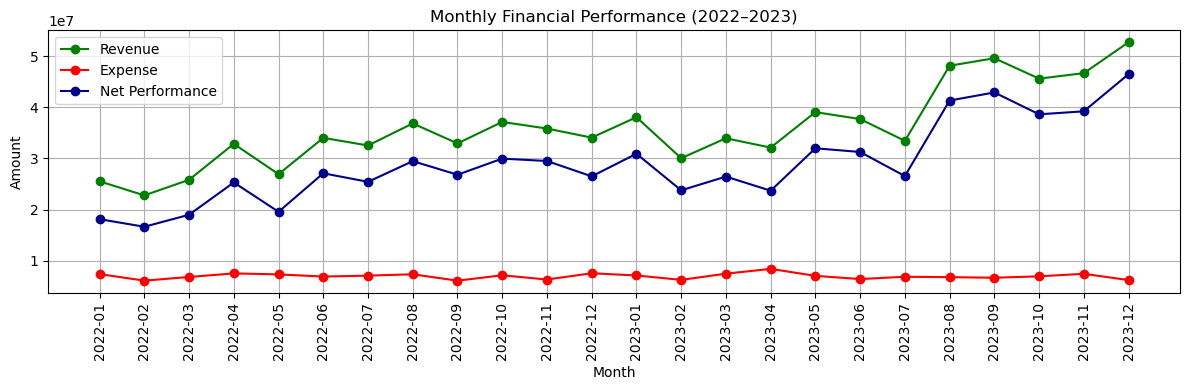

In [28]:
# Step 11: Visualize monthly financial performance

plt.figure(figsize=(12, 4))

plt.plot(
    monthly_pivot.index.astype(str),
    monthly_pivot["Revenue"],
    marker="o",
    label="Revenue",
    color= "green"
)

plt.plot(
    monthly_pivot.index.astype(str),
    monthly_pivot["Expense"].abs(),
    marker="o",
    label="Expense",
    color= "red"
)

plt.plot(
    monthly_pivot.index.astype(str),
    monthly_pivot["Net_Performance"],
    marker="o",
    label="Net Performance",
    color= "darkblue"
)

plt.title("Monthly Financial Performance (2022–2023)")
plt.xlabel("Month")
plt.ylabel("Amount")
plt.xticks(rotation=90)
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()

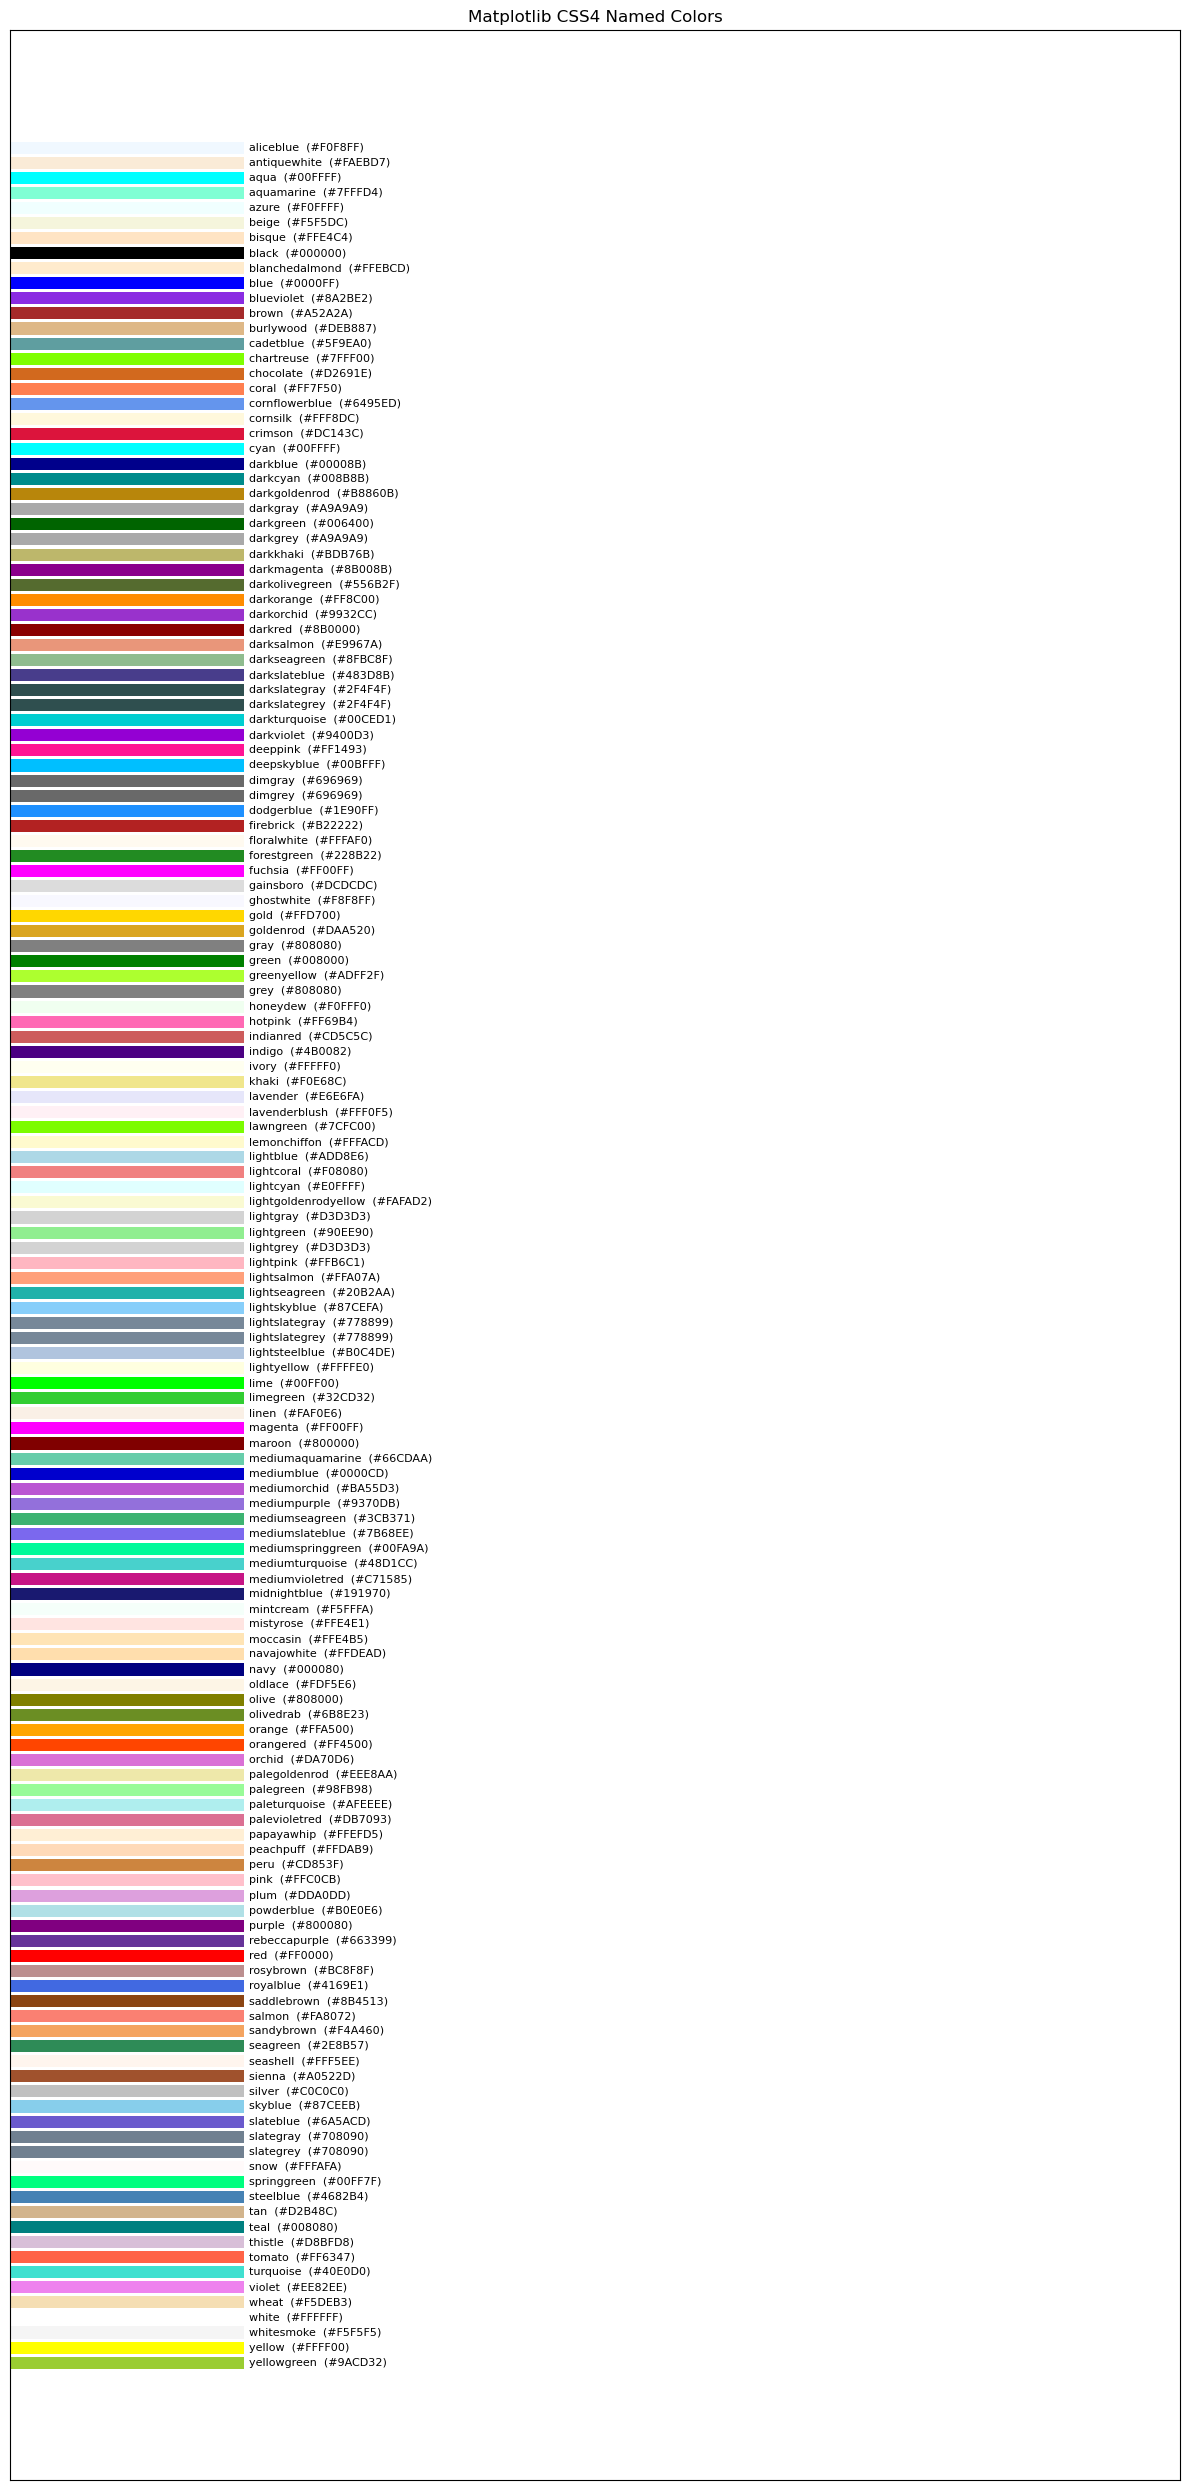

In [27]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

colors = mcolors.CSS4_COLORS

fig, ax = plt.subplots(figsize=(12, 25))

for i, (name, hex_code) in enumerate(colors.items()):
    y = len(colors) - i
    ax.barh(y, 1, color=hex_code)
    ax.text(1.02, y, f"{name}  ({hex_code})",
            va='center', fontsize=8)

ax.set_yticks([])
ax.set_xticks([])
ax.set_xlim(0, 5)
ax.set_title("Matplotlib CSS4 Named Colors")

plt.tight_layout()
plt.show()

In [29]:
# Step 12: Year-over-Year financial performance

yearly_performance = (
    df_eda[df_eda["account_type"].isin(["Revenue", "Expense"])]
    .groupby(["year", "account_type"])
    .agg(
        transaction_count=("transaction_id", "count"),
        total_amount=("amount", "sum")
    )
    .reset_index()
)

yearly_pivot = (
    yearly_performance
    .pivot(
        index="year",
        columns="account_type",
        values=["transaction_count", "total_amount"]
    )
)

# Calculate Net Performance
yearly_pivot[("total_amount", "Net_Performance")] = (
    yearly_pivot[("total_amount", "Revenue")] +
    yearly_pivot[("total_amount", "Expense")]
)

yearly_pivot

transaction_count         total_amount                \
account_type           Expense Revenue      Expense       Revenue   
year                                                                
2022                    2085.0  2406.0 -83861309.16  3.774261e+08   
2023                    2040.0  3108.0 -83879990.64  4.871825e+08   

                              
account_type Net_Performance  
year                          
2022            2.935648e+08  
2023            4.033025e+08

In [30]:
# Step 13: Calculate year-over-year growth

revenue_2022 = yearly_pivot.loc[2022, ("total_amount", "Revenue")]
revenue_2023 = yearly_pivot.loc[2023, ("total_amount", "Revenue")]

net_2022 = yearly_pivot.loc[2022, ("total_amount", "Net_Performance")]
net_2023 = yearly_pivot.loc[2023, ("total_amount", "Net_Performance")]

expense_2022 = yearly_pivot.loc[2022, ("total_amount", "Expense")]
expense_2023 = yearly_pivot.loc[2023, ("total_amount", "Expense")]

revenue_growth = ((revenue_2023 - revenue_2022) / revenue_2022) * 100
net_growth = ((net_2023 - net_2022) / net_2022) * 100
expense_change = ((expense_2023 - expense_2022) / abs(expense_2022)) * 100

print(f"Revenue YoY Growth: {revenue_growth:.2f}%")
print(f"Net Performance YoY Growth: {net_growth:.2f}%")
print(f"Expense YoY Change: {expense_change:.2f}%")

Revenue YoY Growth: 29.08%
Net Performance YoY Growth: 37.38%
Expense YoY Change: -0.02%


In [31]:
# Step 14: Calculate monthly revenue growth

monthly_revenue = (
    df_eda[df_eda["account_type"] == "Revenue"]
    .groupby("year_month")
    .agg(
        transaction_count=("transaction_id", "count"),
        revenue=("amount", "sum")
    )
    .reset_index()
)

monthly_revenue["revenue_growth_pct"] = (
    monthly_revenue["revenue"].pct_change() * 100
)

monthly_revenue

,year_month,transaction_count,revenue,revenue_growth_pct
0,2022-01,176,25538097.88,NaN
1,2022-02,163,22787659.96,-10.769940
2,2022-03,179,25839878.66,13.394173
3,2022-04,207,32862478.97,27.177373
4,2022-05,170,26932607.33,-18.044505
5,2022-06,201,34033298.18,26.364662
6,2022-07,200,32543433.61,-4.377667
7,2022-08,220,36856527.38,13.253346
8,2022-09,204,32948507.24,-10.603332
9,2022-10,246,37149413.47,12.749914


In [32]:
# Step 15: Identify highest and lowest monthly revenue growth

growth_analysis = monthly_revenue.dropna(
    subset=["revenue_growth_pct"]
)

highest_growth = growth_analysis.loc[
    growth_analysis["revenue_growth_pct"].idxmax()
]

lowest_growth = growth_analysis.loc[
    growth_analysis["revenue_growth_pct"].idxmin()
]

print("Highest Monthly Revenue Growth")
print("--------------------------------")
print("Month:", highest_growth["year_month"])
print(f"Growth: {highest_growth['revenue_growth_pct']:.2f}%")
print(f"Revenue: {highest_growth['revenue']:,.2f}")

print("\nLowest Monthly Revenue Growth")
print("--------------------------------")
print("Month:", lowest_growth["year_month"])
print(f"Growth: {lowest_growth['revenue_growth_pct']:.2f}%")
print(f"Revenue: {lowest_growth['revenue']:,.2f}")

Highest Monthly Revenue Growth
--------------------------------
Month: 2023-08
Growth: 43.88%
Revenue: 48,132,079.93

Lowest Monthly Revenue Growth
--------------------------------
Month: 2023-02
Growth: -21.04%
Revenue: 30,059,682.33


In [33]:
# Step 16: Revenue and Expense analysis by business unit

business_financials = (
    df_eda[df_eda["account_type"].isin(["Revenue", "Expense"])]
    .groupby(["business_unit", "account_type"])
    .agg(
        transaction_count=("transaction_id", "count"),
        total_amount=("amount", "sum")
    )
    .reset_index()
)

business_financial_pivot = (
    business_financials
    .pivot(
        index="business_unit",
        columns="account_type",
        values="total_amount"
    )
    .fillna(0)
)

# Calculate net performance
business_financial_pivot["Net_Performance"] = (
    business_financial_pivot["Revenue"] +
    business_financial_pivot["Expense"]
)

# Calculate profit margin
business_financial_pivot["Profit_Margin_%"] = (
    business_financial_pivot["Net_Performance"]
    / business_financial_pivot["Revenue"]
) * 100

business_financial_pivot.sort_values(
    "Net_Performance",
    ascending=False
)

account_type,Expense,Revenue,Net_Performance,Profit_Margin_%
business_unit,,,,
Online,-55303537.71,2.975329e+08,2.422294e+08,81.412632
Retail,-55415143.46,2.856785e+08,2.302633e+08,80.602268
Enterprise,-57022618.63,2.813972e+08,2.243746e+08,79.735897


In [34]:
# Step 17: Revenue and Expense analysis by region

region_financials = (
    df_eda[df_eda["account_type"].isin(["Revenue", "Expense"])]
    .groupby(["region", "account_type"])
    .agg(
        transaction_count=("transaction_id", "count"),
        total_amount=("amount", "sum")
    )
    .reset_index()
)

region_financial_pivot = (
    region_financials
    .pivot(
        index="region",
        columns="account_type",
        values="total_amount"
    )
    .fillna(0)
)

# Calculate net performance
region_financial_pivot["Net_Performance"] = (
    region_financial_pivot["Revenue"] +
    region_financial_pivot["Expense"]
)

# Calculate profit margin
region_financial_pivot["Profit_Margin_%"] = (
    region_financial_pivot["Net_Performance"]
    / region_financial_pivot["Revenue"]
) * 100

region_financial_pivot.sort_values(
    "Net_Performance",
    ascending=False
)

account_type,Expense,Revenue,Net_Performance,Profit_Margin_%
region,,,,
East,-42967914.13,2.221889e+08,1.792210e+08,80.661536
West,-39376077.38,2.141956e+08,1.748196e+08,81.616770
North,-42422551.62,2.138376e+08,1.714151e+08,80.161323
South,-42974756.67,2.143865e+08,1.714117e+08,79.954540


In [35]:
# Step 18: Customer-level revenue analysis

customer_revenue = (
    df_eda[
        (df_eda["account_type"] == "Revenue") &
        (df_eda["customer_id"].notna())
    ]
    .groupby("customer_id")
    .agg(
        transaction_count=("transaction_id", "count"),
        total_revenue=("amount", "sum"),
        average_transaction=("amount", "mean")
    )
    .sort_values("total_revenue", ascending=False)
)

customer_revenue.head(10)

,transaction_count,total_revenue,average_transaction
customer_id,,,
CUST10043,28,4237368.34,151334.583571
CUST10307,24,4221501.03,175895.876250
CUST10237,26,4041968.79,155460.338077
CUST10072,22,3810295.06,173195.230000
CUST10353,23,3791589.90,164851.734783
CUST10061,23,3767369.55,163798.676087
CUST10228,23,3720464.00,161759.304348
CUST10052,23,3654626.52,158896.805217
CUST10049,18,3593347.87,199630.437222


In [36]:
# Step 19: Calculate top customer revenue contribution

top_10_customer_revenue = customer_revenue.head(10)["total_revenue"].sum()

total_revenue = df_eda.loc[
    df_eda["account_type"] == "Revenue",
    "amount"
].sum()

top_10_contribution_pct = (
    top_10_customer_revenue / total_revenue
) * 100

print(f"Top 10 Customer Revenue: {top_10_customer_revenue:,.2f}")
print(f"Total Revenue: {total_revenue:,.2f}")
print(f"Top 10 Revenue Contribution: {top_10_contribution_pct:.2f}%")

Top 10 Customer Revenue: 38,424,202.77
Total Revenue: 864,608,592.20
Top 10 Revenue Contribution: 4.44%


In [37]:
# Step 20: Vendor-level expense analysis

vendor_expense = (
    df_eda[
        (df_eda["account_type"] == "Expense") &
        (df_eda["vendor_id"].notna())
    ]
    .groupby("vendor_id")
    .agg(
        transaction_count=("transaction_id", "count"),
        total_expense=("amount", "sum"),
        average_transaction=("amount", "mean")
    )
    .sort_values("total_expense")
)

vendor_expense.head(10)

,transaction_count,total_expense,average_transaction
vendor_id,,,
VEND1095,63,-2831132.99,-44938.618889
VEND1065,65,-2768458.67,-42591.671846
VEND1018,61,-2731307.59,-44775.534262
VEND1117,60,-2677039.00,-44617.316667
VEND1032,53,-2474393.70,-46686.673585
VEND1059,56,-2461698.04,-43958.893571
VEND1078,51,-2450171.87,-48042.585686
VEND1100,57,-2440780.33,-42820.707544
VEND1112,59,-2354540.77,-39907.470678


In [38]:
# Step 21: Calculate top 10 vendor expense contribution

top_10_vendor_expense = vendor_expense.head(10)["total_expense"].sum()

total_expense = df_eda.loc[
    df_eda["account_type"] == "Expense",
    "amount"
].sum()

top_10_expense_contribution_pct = (
    abs(top_10_vendor_expense) / abs(total_expense)
) * 100

print(f"Top 10 Vendor Expense: {top_10_vendor_expense:,.2f}")
print(f"Total Expense: {total_expense:,.2f}")
print(
    f"Top 10 Vendor Expense Contribution: "
    f"{top_10_expense_contribution_pct:.2f}%"
)

Top 10 Vendor Expense: -25,542,918.62
Total Expense: -167,741,299.80
Top 10 Vendor Expense Contribution: 15.23%


In [39]:
# Step 22: Category-wise financial performance by business unit

category_business_summary = (
    df_eda[
        df_eda["account_type"].isin(["Revenue", "Expense"])
    ]
    .groupby(["business_unit", "category", "account_type"])
    .agg(
        transaction_count=("transaction_id", "count"),
        total_amount=("amount", "sum")
    )
    .reset_index()
)

category_business_summary

,business_unit,category,account_type,transaction_count,total_amount
0,Enterprise,Marketing,Expense,240,-9.638474e+06
1,Enterprise,Other,Expense,247,-1.035778e+07
2,Enterprise,Payroll,Expense,235,-9.215822e+06
3,Enterprise,Product,Revenue,593,9.384566e+07
4,Enterprise,Rent,Expense,221,-9.069122e+06
5,Enterprise,Service,Revenue,615,9.476184e+07
6,Enterprise,Subscription,Revenue,600,9.278970e+07
7,Enterprise,Supplies,Expense,227,-9.208837e+06
8,Enterprise,Utilities,Expense,238,-9.532584e+06
9,Online,Marketing,Expense,232,-9.524029e+06


In [40]:
# Step 23: Create business unit and category pivot

business_category_pivot = (
    category_business_summary
    .pivot_table(
        index="business_unit",
        columns=["category", "account_type"],
        values="total_amount",
        aggfunc="sum",
        fill_value=0
    )
)

business_category_pivot

category,Marketing,Other,Payroll,Product,Rent,Service,Subscription,Supplies,Utilities
account_type,Expense,Expense,Expense,Revenue,Expense,Revenue,Revenue,Expense,Expense
business_unit,,,,,,,,,
Enterprise,-9638473.64,-10357779.11,-9215822.49,93845659.75,-9069121.85,9.476184e+07,92789704.93,-9208837.47,-9532584.07
Online,-9524029.31,-10462935.69,-7786557.59,94305503.42,-9358871.10,1.034334e+08,99794023.80,-9203003.53,-8968140.49
Retail,-9797655.08,-9138627.17,-8304139.03,95971345.11,-8956089.97,9.043934e+07,99267782.37,-9335667.70,-9882964.51


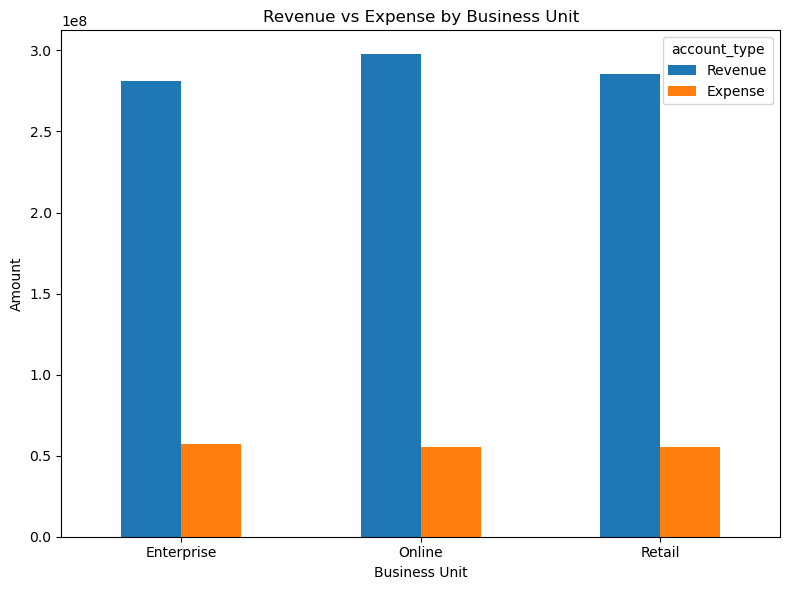

In [42]:
# Step 24: Business Unit Revenue vs Expense Visualization

plot_data = business_financial_pivot[
    ["Revenue", "Expense"]
].copy()

# Convert Expense to positive magnitude for visualization
plot_data["Expense"] = plot_data["Expense"].abs()

ax = plot_data.plot(
    kind="bar",
    figsize=(8, 6)
)

ax.set_title("Revenue vs Expense by Business Unit")
ax.set_xlabel("Business Unit")
ax.set_ylabel("Amount")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

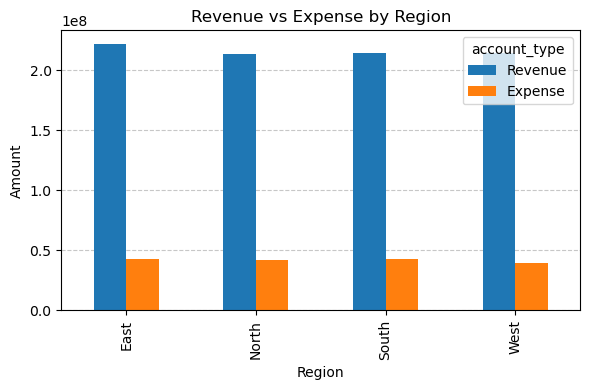

In [55]:
# Step 25: Region Revenue vs Expense Visualization

region_plot_data = region_financial_pivot[
    ["Revenue", "Expense"]
].copy()

# Convert Expense to positive magnitude for visualization
region_plot_data["Expense"] = region_plot_data["Expense"].abs()

ax = region_plot_data.plot(
    kind="bar",
    figsize=(6, 4)
)

ax.set_title("Revenue vs Expense by Region")
ax.set_xlabel("Region")
ax.set_ylabel("Amount")
ax.tick_params(axis="x", rotation=90)

# Add gridlines
ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.7
)

# Keep gridlines behind the bars
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

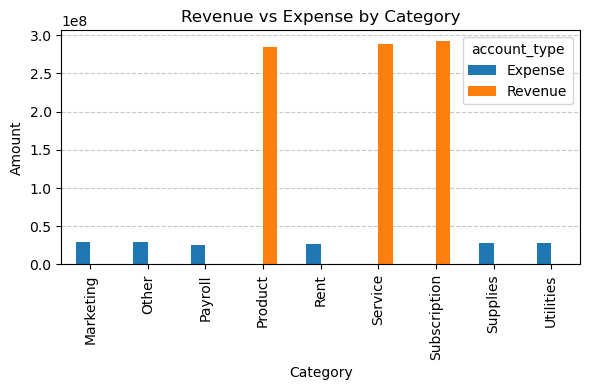

In [56]:
# Step 26: Category-wise Revenue vs Expense Visualization

category_financials = (
    df_eda[
        df_eda["account_type"].isin(["Revenue", "Expense"])
    ]
    .groupby(["category", "account_type"])
    .agg(
        total_amount=("amount", "sum")
    )
    .reset_index()
)

category_plot_data = (
    category_financials
    .pivot(
        index="category",
        columns="account_type",
        values="total_amount"
    )
    .fillna(0)
)

# Convert Expense to positive magnitude for visualization
if "Expense" in category_plot_data.columns:
    category_plot_data["Expense"] = category_plot_data["Expense"].abs()

ax = category_plot_data.plot(
    kind="bar",
    figsize=(6, 4)
)

ax.set_title("Revenue vs Expense by Category")
ax.set_xlabel("Category")
ax.set_ylabel("Amount")
ax.tick_params(axis="x", rotation=90)

# Add gridlines
ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.7
)

# Keep gridlines behind the bars
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [57]:
# Step 27: Category contribution analysis

category_contribution = (
    df_eda[
        df_eda["account_type"].isin(["Revenue", "Expense"])
    ]
    .groupby(["category", "account_type"])["amount"]
    .sum()
    .reset_index()
)

# Calculate contribution separately for Revenue and Expense
category_contribution["contribution_pct"] = (
    category_contribution
    .groupby("account_type")["amount"]
    .transform(
        lambda x: (x.abs() / x.abs().sum()) * 100
    )
)

category_contribution = category_contribution.sort_values(
    ["account_type", "contribution_pct"],
    ascending=[True, False]
)

category_contribution

,category,account_type,amount,contribution_pct
1,Other,Expense,-2.995934e+07,17.860445
0,Marketing,Expense,-2.896016e+07,17.264775
8,Utilities,Expense,-2.838369e+07,16.921110
7,Supplies,Expense,-2.774751e+07,16.541847
4,Rent,Expense,-2.738408e+07,16.325188
2,Payroll,Expense,-2.530652e+07,15.086636
6,Subscription,Revenue,2.918515e+08,33.755333
5,Service,Revenue,2.886346e+08,33.383264
3,Product,Revenue,2.841225e+08,32.861402


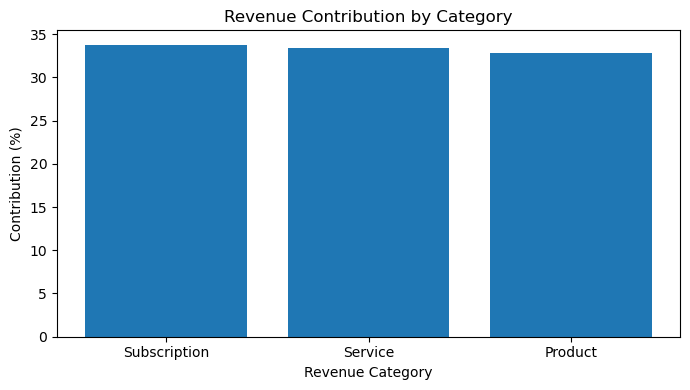

In [61]:
# Step 28: Category contribution visualization

revenue_contribution = category_contribution[
    category_contribution["account_type"] == "Revenue"
].sort_values("contribution_pct", ascending=False)

expense_contribution = category_contribution[
    category_contribution["account_type"] == "Expense"
].sort_values("contribution_pct", ascending=False)

# Revenue contribution chart
plt.figure(figsize=(7, 4))

plt.bar(
    revenue_contribution["category"],
    revenue_contribution["contribution_pct"]
)

plt.title("Revenue Contribution by Category")
plt.xlabel("Revenue Category")
plt.ylabel("Contribution (%)")

plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

plt.grid restored successfully!
<class 'method'>


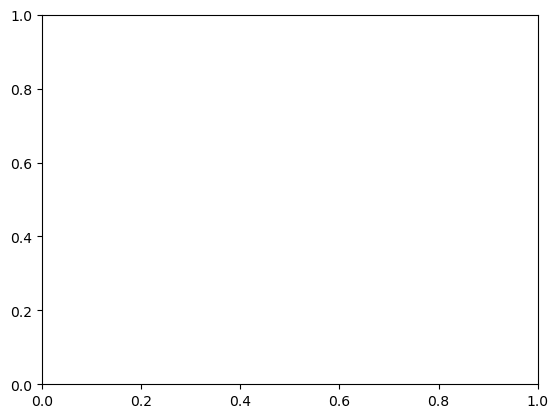

In [59]:
# Restore Matplotlib grid function

import matplotlib.pyplot as plt

plt.grid = plt.gca().grid

print("plt.grid restored successfully!")
print(type(plt.grid))

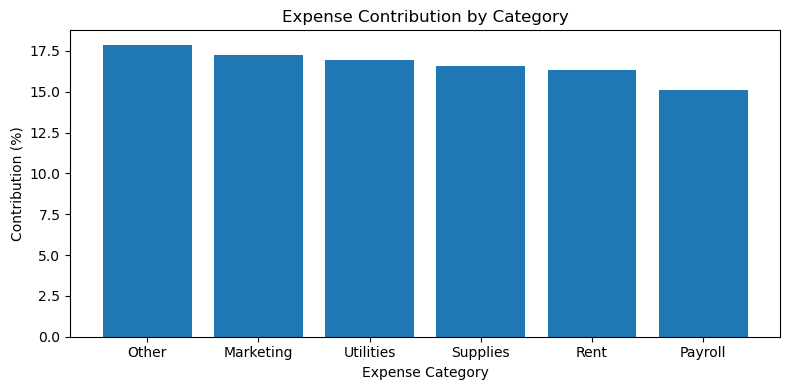

In [63]:
# Step 29: Expense Category Contribution Visualization

expense_contribution = category_contribution[
    category_contribution["account_type"] == "Expense"
].sort_values("contribution_pct", ascending=False)

plt.figure(figsize=(8, 4))

plt.bar(
    expense_contribution["category"],
    expense_contribution["contribution_pct"]
)

plt.title("Expense Contribution by Category")
plt.xlabel("Expense Category")
plt.ylabel("Contribution (%)")

plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

In [64]:
# Step 30: Year-wise Financial Performance Visualization

yearly_financials = (
    df_eda[
        df_eda["account_type"].isin(["Revenue", "Expense"])
    ]
    .groupby(["year", "account_type"])["amount"]
    .sum()
    .unstack(fill_value=0)
)

# Calculate Net Performance
yearly_financials["Net_Performance"] = (
    yearly_financials["Revenue"]
    + yearly_financials["Expense"]
)

print(yearly_financials)

account_type      Expense       Revenue  Net_Performance
year                                                    
2022         -83861309.16  3.774261e+08     2.935648e+08
2023         -83879990.64  4.871825e+08     4.033025e+08


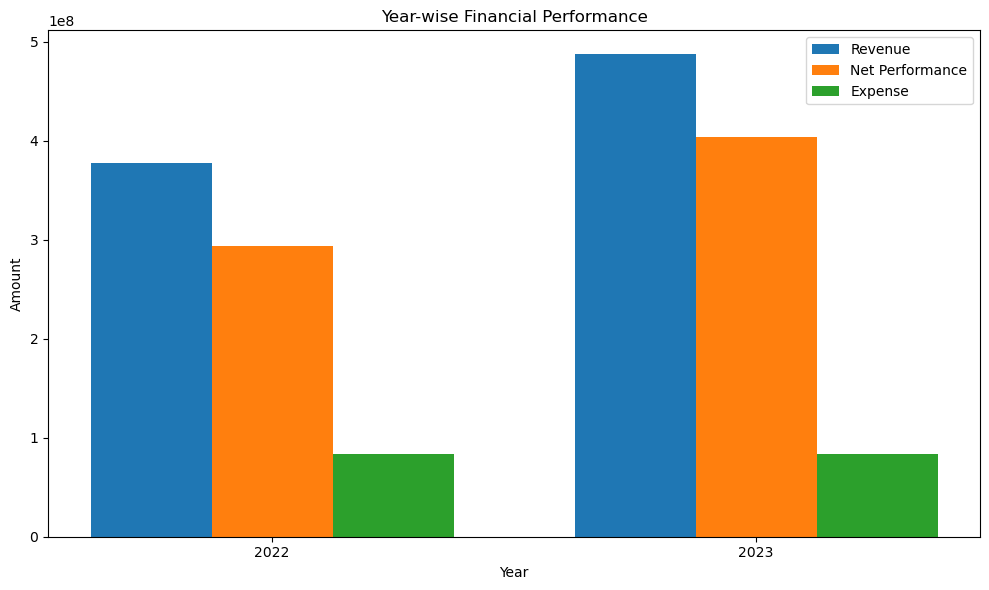

In [65]:
# Step 31: Year-wise Financial Performance Visualization

plt.figure(figsize=(10, 6))

x = yearly_financials.index

plt.bar(
    x - 0.25,
    yearly_financials["Revenue"],
    width=0.25,
    label="Revenue"
)

plt.bar(
    x,
    yearly_financials["Net_Performance"],
    width=0.25,
    label="Net Performance"
)

plt.bar(
    x + 0.25,
    yearly_financials["Expense"].abs(),
    width=0.25,
    label="Expense"
)

plt.title("Year-wise Financial Performance")
plt.xlabel("Year")
plt.ylabel("Amount")

plt.xticks(x)
plt.legend()

plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

In [66]:
# Step 32: EDA Key Findings Summary

eda_key_findings = {
    "Revenue YoY Growth": "29.08%",
    "Net Performance YoY Growth": "37.38%",
    "Expense YoY Change": "-0.02%",
    "Highest Monthly Revenue Growth": "2023-08 (43.88%)",
    "Lowest Monthly Revenue Growth": "2023-02 (-21.04%)",
    "Top Revenue Category": "Subscription (33.76%)",
    "Top Expense Category": "Other (17.86%)",
    "Top Business Unit by Revenue": "Online",
    "Top Region by Revenue": "East",
    "Top 10 Customer Revenue Contribution": "4.44%",
    "Top 10 Vendor Expense Contribution": "15.23%"
}

eda_key_findings_df = pd.DataFrame(
    list(eda_key_findings.items()),
    columns=["Metric", "Finding"]
)

eda_key_findings_df

,Metric,Finding
0,Revenue YoY Growth,29.08%
1,Net Performance YoY Growth,37.38%
2,Expense YoY Change,-0.02%
3,Highest Monthly Revenue Growth,2023-08 (43.88%)
4,Lowest Monthly Revenue Growth,2023-02 (-21.04%)
5,Top Revenue Category,Subscription (33.76%)
6,Top Expense Category,Other (17.86%)
7,Top Business Unit by Revenue,Online
8,Top Region by Revenue,East
9,Top 10 Customer Revenue Contribution,4.44%


# CRISP-DM — Data Understanding & Exploratory Data Analysis (EDA)

## EDA Summary

The cleaned financial transaction dataset was explored to understand its structure, distributions, financial performance, trends, and key business dimensions.

### Dataset Overview

- Total transactions: **10,400**
- Analysis period: **2022-01-01 to 2023-12-30**
- Account types: **5**
- Business units: **3**
- Regions: **4**
- Revenue categories: **3**
- Expense categories: **6**

### Data Quality Observations

- Missing values in required fields: **0**
- Duplicate rows: **0**
- Unique transaction IDs: **10,400**
- Invalid transaction dates: **0**
- Invalid amounts: **0**
- Orphan customer IDs: **0**
- Orphan vendor IDs: **0**
- Accounting sign validation: **PASSED**
- Final cleaning validation: **PASSED**

### Financial Performance Findings

- Revenue YoY Growth: **29.08%**
- Net Performance YoY Growth: **37.38%**
- Expense YoY Change: **-0.02%**
- 2022 Revenue: **377.43M**
- 2023 Revenue: **487.18M**
- 2022 Net Performance: **293.56M**
- 2023 Net Performance: **403.30M**

### Monthly Trend Findings

- Highest monthly revenue growth: **August 2023 — 43.88%**
- Lowest monthly revenue growth: **February 2023 — -21.04%**
- Revenue showed substantial improvement during the second half of 2023.

### Category Findings

#### Revenue

- Subscription contribution: **33.76%**
- Service contribution: **33.38%**
- Product contribution: **32.86%**

Revenue is relatively well diversified across the three revenue categories.

#### Expense

- Other contribution: **17.86%**
- Marketing contribution: **17.26%**
- Utilities contribution: **16.92%**
- Supplies contribution: **16.54%**
- Rent contribution: **16.33%**
- Payroll contribution: **15.09%**

Expense contribution is relatively evenly distributed across the six expense categories.

### Business Unit Findings

- Highest revenue business unit: **Online**
- Online generated the highest total revenue among the three business units.
- Revenue and expense levels were broadly comparable across business units.

### Regional Findings

- Highest revenue region: **East**
- West recorded the highest profit margin among the regions.
- Regional financial performance was relatively balanced.

### Customer & Vendor Concentration

- Top 10 customers contributed **4.44%** of total revenue.
- Top 10 vendors accounted for **15.23%** of total expense.

This indicates that revenue is not heavily concentrated among a small number of customers, while vendor expenses show comparatively higher concentration.

## Key EDA Conclusion

The exploratory analysis indicates strong financial improvement from 2022 to 2023. Revenue increased significantly while total expense remained nearly unchanged, resulting in a stronger increase in net performance. Revenue is diversified across Product, Service, and Subscription categories, while expenses are distributed relatively evenly across major expense categories.



# CRISP-DM — Data Preparation

## Objective

The objective of the Data Preparation phase is to transform the validated and explored data into a structured analytical dataset suitable for KPI analysis, modeling, visualization, and business decision-making.

## Data Preparation Workflow

1. Feature Engineering
2. Time-based Feature Preparation
3. Financial KPI Feature Creation
4. Customer and Vendor Attribute Integration
5. Analytical Dataset Creation
6. Data Preparation Validation

## Input

The validated cleaned financial transaction dataset contains:

- **10,400 transactions**
- **10 columns**
- Transaction period: **2022-01-01 to 2023-12-30**

The original cleaned dataset will be preserved, and derived features will be created in separate analytical datasets.

## Expected Output

A validated analytical dataset containing the required transaction-level and derived features for subsequent financial analysis, modeling, dashboard development, and business recommendations.

In [67]:
# Data Preparation — Cell 1
# Load the validated cleaned transaction dataset

df_prep = df_eda.copy()

print("Data Preparation dataset loaded successfully!")
print("Rows:", df_prep.shape[0])
print("Columns:", df_prep.shape[1])
print("\nColumns:")
print(df_prep.columns.tolist())

Data Preparation dataset loaded successfully!
Rows: 10400
Columns: 14

Columns:
['transaction_id', 'transaction_date', 'amount', 'account_type', 'category', 'business_unit', 'region', 'customer_id', 'vendor_id', 'description', 'year', 'month', 'month_name', 'year_month']


In [68]:
# Data Preparation — Cell 2
# Create financial sign and absolute amount features

df_prep["amount_abs"] = df_prep["amount"].abs()

df_prep["amount_sign"] = df_prep["amount"].apply(
    lambda x: "Positive" if x > 0
    else "Negative" if x < 0
    else "Zero"
)

print("Financial sign features created successfully!")

print("\nNew columns:")
print(["amount_abs", "amount_sign"])

print("\nAmount sign distribution:")
print(df_prep["amount_sign"].value_counts())

print("\nData shape:", df_prep.shape)

Financial sign features created successfully!

New columns:
['amount_abs', 'amount_sign']

Amount sign distribution:
amount_sign
Positive    6275
Negative    4125
Name: count, dtype: int64

Data shape: (10400, 16)


In [69]:
# Data Preparation — Cell 3
# Create transaction-level financial classification

df_prep["financial_flow"] = df_prep["account_type"].apply(
    lambda x: "Income" if x == "Revenue"
    else "Cost" if x == "Expense"
    else "Balance Sheet"
)

print("Financial flow classification created successfully!")

print("\nFinancial flow distribution:")
print(df_prep["financial_flow"].value_counts())

print("\nAccount type vs financial flow:")
print(
    pd.crosstab(
        df_prep["account_type"],
        df_prep["financial_flow"]
    )
)

print("\nData shape:", df_prep.shape)

Financial flow classification created successfully!

Financial flow distribution:
financial_flow
Income           5514
Cost             4125
Balance Sheet     761
Name: count, dtype: int64

Account type vs financial flow:
financial_flow  Balance Sheet  Cost  Income
account_type                               
Asset                     315     0       0
Equity                    244     0       0
Expense                     0  4125       0
Liability                 202     0       0
Revenue                     0     0    5514

Data shape: (10400, 17)


In [70]:
# Data Preparation — Cell 4
# Create separate revenue and expense amount features

df_prep["revenue_amount"] = df_prep["amount"].where(
    df_prep["account_type"] == "Revenue",
    0
)

df_prep["expense_amount"] = df_prep["amount"].where(
    df_prep["account_type"] == "Expense",
    0
)

print("Revenue and expense features created successfully!")

print("\nRevenue transactions:")
print((df_prep["revenue_amount"] != 0).sum())

print("\nExpense transactions:")
print((df_prep["expense_amount"] != 0).sum())

print("\nRevenue total:")
print(df_prep["revenue_amount"].sum())

print("\nExpense total:")
print(df_prep["expense_amount"].sum())

print("\nData shape:", df_prep.shape)

Revenue and expense features created successfully!

Revenue transactions:
5514

Expense transactions:
4125

Revenue total:
864608592.2

Expense total:
-167741299.8

Data shape: (10400, 19)


In [71]:
# Data Preparation — Cell 5
# Create transaction-level net performance feature

df_prep["net_performance"] = (
    df_prep["revenue_amount"] +
    df_prep["expense_amount"]
)

print("Net performance feature created successfully!")

print("\nNet Performance total:")
print(df_prep["net_performance"].sum())

print("\nRevenue total:")
print(df_prep["revenue_amount"].sum())

print("\nExpense total:")
print(df_prep["expense_amount"].sum())

print("\nValidation:")
print(
    "Net Performance = Revenue + Expense:",
    df_prep["net_performance"].sum()
    == (
        df_prep["revenue_amount"].sum()
        + df_prep["expense_amount"].sum()
    )
)

print("\nData shape:", df_prep.shape)

Net performance feature created successfully!

Net Performance total:
696867292.4

Revenue total:
864608592.2

Expense total:
-167741299.8

Validation:
Net Performance = Revenue + Expense: False

Data shape: (10400, 20)


In [74]:
# Data Preparation — Cell 5A
# Validate Net Performance calculation with tolerance

import numpy as np

expected_net_performance = (
    df_prep["revenue_amount"].sum()
    + df_prep["expense_amount"].sum()
)

actual_net_performance = df_prep["net_performance"].sum()

difference = actual_net_performance - expected_net_performance

print("Expected Net Performance:", expected_net_performance)
print("Actual Net Performance:", actual_net_performance)
print("Difference:", difference)

print(
    "Net Performance validation:",
    np.isclose(
        actual_net_performance,
        expected_net_performance,
        rtol=1e-10,
        atol=1e-6
    )
)

Expected Net Performance: 696867292.4000001
Actual Net Performance: 696867292.4
Difference: -1.1920928955078125e-07
Net Performance validation: True


In [75]:
# Data Preparation — Cell 6
# Create transaction-level revenue margin feature

df_prep["revenue_margin_pct"] = np.where(
    df_prep["account_type"] == "Revenue",
    100,
    np.nan
)

print("Revenue margin feature created successfully!")

print("\nRevenue margin values:")
print(df_prep["revenue_margin_pct"].value_counts(dropna=False))

print("\nData shape:", df_prep.shape)

Revenue margin feature created successfully!

Revenue margin values:
revenue_margin_pct
100.0    5514
NaN      4886
Name: count, dtype: int64

Data shape: (10400, 21)


In [76]:
# Remove non-meaningful transaction-level margin feature

df_prep.drop(columns=["revenue_margin_pct"], inplace=True)

print("Non-meaningful margin feature removed successfully!")
print("Current dataset shape:", df_prep.shape)

Non-meaningful margin feature removed successfully!
Current dataset shape: (10400, 20)


In [77]:
# Data Preparation — Cell 7
# Create revenue and expense transaction flags

df_prep["is_revenue"] = (
    df_prep["account_type"] == "Revenue"
).astype(int)

df_prep["is_expense"] = (
    df_prep["account_type"] == "Expense"
).astype(int)

print("Revenue and expense flags created successfully!")

print("\nRevenue flag distribution:")
print(df_prep["is_revenue"].value_counts())

print("\nExpense flag distribution:")
print(df_prep["is_expense"].value_counts())

print("\nFlag validation:")

print(
    "Revenue flag count:",
    df_prep["is_revenue"].sum()
)

print(
    "Expected Revenue count:",
    (df_prep["account_type"] == "Revenue").sum()
)

print(
    "Expense flag count:",
    df_prep["is_expense"].sum()
)

print(
    "Expected Expense count:",
    (df_prep["account_type"] == "Expense").sum()
)

print("\nData shape:", df_prep.shape)

Revenue and expense flags created successfully!

Revenue flag distribution:
is_revenue
1    5514
0    4886
Name: count, dtype: int64

Expense flag distribution:
is_expense
0    6275
1    4125
Name: count, dtype: int64

Flag validation:
Revenue flag count: 5514
Expected Revenue count: 5514
Expense flag count: 4125
Expected Expense count: 4125

Data shape: (10400, 22)


In [78]:
# Data Preparation — Cell 8
# Create quarterly analytical features

df_prep["quarter"] = df_prep["transaction_date"].dt.quarter

df_prep["year_quarter"] = (
    df_prep["transaction_date"].dt.year.astype(str)
    + "-Q"
    + df_prep["quarter"].astype(str)
)

print("Quarterly features created successfully!")

print("\nQuarter distribution:")
print(df_prep["quarter"].value_counts().sort_index())

print("\nYear-Quarter distribution:")
print(df_prep["year_quarter"].value_counts().sort_index())

print("\nData shape:", df_prep.shape)


Quarterly features created successfully!

Quarter distribution:
quarter
1    2407
2    2593
3    2661
4    2739
Name: count, dtype: int64

Year-Quarter distribution:
year_quarter
2022-Q1    1149
2022-Q2    1230
2022-Q3    1217
2022-Q4    1298
2023-Q1    1258
2023-Q2    1363
2023-Q3    1444
2023-Q4    1441
Name: count, dtype: int64

Data shape: (10400, 24)


In [89]:
# Data Preparation — Cell 9
# Check variables related to customer and vendor master data

customer_vendor_variables = [
    name for name in globals()
    if any(keyword in name.lower() for keyword in ["customer", "vendor"])
]

print("Customer/Vendor related variables found:")

if customer_vendor_variables:
    for name in customer_vendor_variables:
        value = globals()[name]
        print(f"{name}: {type(value).__name__}")
else:
    print("No customer/vendor master variables currently loaded.")

Customer/Vendor related variables found:
customer_revenue: DataFrame
top_10_customer_revenue: float64
vendor_expense: DataFrame
top_10_vendor_expense: float64
customer_vendor_variables: list
customers_path: str
vendors_path: str
df_customers_prep: DataFrame
df_vendors_prep: DataFrame


In [88]:
# Data Preparation — Cell 9
# Load Customer and Vendor master datasets

import os

project_root = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))

customers_path = os.path.join(
    project_root,
    "02_Raw_Data",
    "Customers.csv"
)

vendors_path = os.path.join(
    project_root,
    "02_Raw_Data",
    "Vendors.csv"
)

df_customers_prep = pd.read_csv(customers_path)
df_vendors_prep = pd.read_csv(vendors_path)

print("Customer and Vendor master datasets loaded successfully!")

print("\nCustomer Master:")
print("Rows:", df_customers_prep.shape[0])
print("Columns:", df_customers_prep.shape[1])
print("Columns:", df_customers_prep.columns.tolist())

print("\nVendor Master:")
print("Rows:", df_vendors_prep.shape[0])
print("Columns:", df_vendors_prep.shape[1])
print("Columns:", df_vendors_prep.columns.tolist())

Customer and Vendor master datasets loaded successfully!

Customer Master:
Rows: 400
Columns: 6
Columns: ['customer_id', 'customer_name', 'segment', 'join_date', 'region', 'status']

Vendor Master:
Rows: 120
Columns: 5
Columns: ['vendor_id', 'vendor_name', 'category', 'region', 'active']


In [90]:
# Data Preparation — Cell 10
# Validate Customer Master before integration

print("CUSTOMER MASTER VALIDATION")
print("=" * 50)

print("\nRows:", df_customers_prep.shape[0])
print("Columns:", df_customers_prep.shape[1])

print("\nMissing values:")
print(df_customers_prep.isna().sum())

print("\nDuplicate customer IDs:")
print(df_customers_prep["customer_id"].duplicated().sum())

print("\nUnique customer IDs:")
print(df_customers_prep["customer_id"].nunique())

print("\nCustomer ID uniqueness:")
print(df_customers_prep["customer_id"].is_unique)

print("\nValidation result:")

customer_validation_passed = (
    df_customers_prep["customer_id"].notna().all()
    and df_customers_prep["customer_id"].is_unique
)

print(
    "CUSTOMER MASTER VALIDATION:",
    "PASSED" if customer_validation_passed else "FAILED"
)

CUSTOMER MASTER VALIDATION

Rows: 400
Columns: 6

Missing values:
customer_id      0
customer_name    0
segment          0
join_date        0
region           0
status           0
dtype: int64

Duplicate customer IDs:
0

Unique customer IDs:
400

Customer ID uniqueness:
True

Validation result:
CUSTOMER MASTER VALIDATION: PASSED


In [93]:
# Data Preparation — Cell 11
# Validate Vendor Master before integration

print("VENDOR MASTER VALIDATION")
print("=" * 50)

print("\nRows:", df_vendors_prep.shape[0])
print("Columns:", df_vendors_prep.shape[1])

print("\nMissing values:")
print(df_vendors_prep.isna().sum())

print("\nDuplicate vendor IDs:")
print(df_vendors_prep["vendor_id"].duplicated().sum())

print("\nUnique vendor IDs:")
print(df_vendors_prep["vendor_id"].nunique())

print("\nVendor ID uniqueness:")
print(df_vendors_prep["vendor_id"].is_unique)

print("\nValidation result:")

vendor_validation_passed = (
    df_vendors_prep["vendor_id"].notna().all()
    and df_vendors_prep["vendor_id"].is_unique
)

print(
    "VENDOR MASTER VALIDATION:",
    "PASSED" if vendor_validation_passed else "FAILED"
)

VENDOR MASTER VALIDATION

Rows: 120
Columns: 5

Missing values:
vendor_id      0
vendor_name    0
category       0
region         0
active         0
dtype: int64

Duplicate vendor IDs:
0

Unique vendor IDs:
120

Vendor ID uniqueness:
True

Validation result:
VENDOR MASTER VALIDATION: PASSED


In [94]:
# Data Preparation — Cell 12
# Validate transaction-to-master ID coverage

print("TRANSACTION → MASTER ID COVERAGE VALIDATION")
print("=" * 60)

# Customer ID coverage
transaction_customer_ids = set(
    df_prep["customer_id"].dropna().unique()
)

master_customer_ids = set(
    df_customers_prep["customer_id"].dropna().unique()
)

orphan_customer_ids = transaction_customer_ids - master_customer_ids

# Vendor ID coverage
transaction_vendor_ids = set(
    df_prep["vendor_id"].dropna().unique()
)

master_vendor_ids = set(
    df_vendors_prep["vendor_id"].dropna().unique()
)

orphan_vendor_ids = transaction_vendor_ids - master_vendor_ids


print("\nCustomer ID Coverage")
print("Unique transaction customer IDs:", len(transaction_customer_ids))
print("Unique master customer IDs:", len(master_customer_ids))
print("Orphan customer IDs:", len(orphan_customer_ids))

print("\nVendor ID Coverage")
print("Unique transaction vendor IDs:", len(transaction_vendor_ids))
print("Unique master vendor IDs:", len(master_vendor_ids))
print("Orphan vendor IDs:", len(orphan_vendor_ids))


coverage_validation_passed = (
    len(orphan_customer_ids) == 0
    and len(orphan_vendor_ids) == 0
)

print("\nValidation result:")
print(
    "TRANSACTION → MASTER ID COVERAGE:",
    "PASSED" if coverage_validation_passed else "FAILED"
)

TRANSACTION → MASTER ID COVERAGE VALIDATION

Customer ID Coverage
Unique transaction customer IDs: 372
Unique master customer IDs: 400
Orphan customer IDs: 0

Vendor ID Coverage
Unique transaction vendor IDs: 120
Unique master vendor IDs: 120
Orphan vendor IDs: 0

Validation result:
TRANSACTION → MASTER ID COVERAGE: PASSED


In [95]:
# Data Preparation — Cell 13
# Integrate customer master attributes

customer_columns = [
    "customer_id",
    "customer_name",
    "segment",
    "join_date",
    "status"
]

df_prep = df_prep.merge(
    df_customers_prep[customer_columns],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

print("Customer attributes merged successfully!")

print("\nData shape after customer merge:")
print(df_prep.shape)

print("\nCustomer attributes added:")
print([
    "customer_name",
    "segment",
    "join_date",
    "status"
])

print("\nMissing values in merged customer attributes:")
print(
    df_prep[
        ["customer_name", "segment", "join_date", "status"]
    ].isna().sum()
)

print("\nRow-count validation:")
print(
    "Original rows:", 10400
)
print(
    "Rows after merge:", df_prep.shape[0]
)

print(
    "Customer merge validation:",
    "PASSED" if df_prep.shape[0] == 10400 else "FAILED"
)

Customer attributes merged successfully!

Data shape after customer merge:
(10400, 28)

Customer attributes added:
['customer_name', 'segment', 'join_date', 'status']

Missing values in merged customer attributes:
customer_name    4886
segment          4886
join_date        4886
status           4886
dtype: int64

Row-count validation:
Original rows: 10400
Rows after merge: 10400
Customer merge validation: PASSED


In [99]:
# Data Preparation — Cell 14
# Clean and rename overlapping vendor/customer attributes

df_prep.rename(
    columns={
        "category_x": "transaction_category",
        "category_y": "vendor_category",
        "region_x": "transaction_region",
        "region_y": "vendor_region"
    },
    inplace=True
)

print("Overlapping columns renamed successfully!")

print("\nCategory columns:")
print([
    col for col in df_prep.columns
    if "category" in col
])

print("\nRegion columns:")
print([
    col for col in df_prep.columns
    if "region" in col
])

print("\nVendor attributes:")
print([
    "vendor_name",
    "vendor_category",
    "vendor_region",
    "active"
])

print("\nMissing values in vendor attributes:")
print(
    df_prep[
        ["vendor_name", "vendor_category", "vendor_region", "active"]
    ].isna().sum()
)

print("\nData shape:", df_prep.shape)

print("\nVendor merge row-count validation:")
print(
    "PASSED" if df_prep.shape[0] == 10400 else "FAILED"
)

Overlapping columns renamed successfully!

Category columns:
['transaction_category', 'vendor_category']

Region columns:
['transaction_region', 'vendor_region']

Vendor attributes:
['vendor_name', 'vendor_category', 'vendor_region', 'active']

Missing values in vendor attributes:
vendor_name        6275
vendor_category    6275
vendor_region      6275
active             6275
dtype: int64

Data shape: (10400, 32)

Vendor merge row-count validation:
PASSED


In [100]:
# Data Preparation — Cell 15
# Final validation of the analytical dataset

print("FINAL DATA PREPARATION VALIDATION")
print("=" * 60)

# 1. Row count
expected_rows = 10400
actual_rows = df_prep.shape[0]

print("\n1. Row Count")
print("Expected:", expected_rows)
print("Actual:", actual_rows)

# 2. Transaction ID uniqueness
unique_transaction_ids = df_prep["transaction_id"].nunique()

print("\n2. Transaction ID Uniqueness")
print("Unique transaction IDs:", unique_transaction_ids)

# 3. Required analytical columns
required_columns = [
    "transaction_id",
    "transaction_date",
    "amount",
    "account_type",
    "transaction_category",
    "business_unit",
    "transaction_region",
    "customer_id",
    "vendor_id",
    "year",
    "month",
    "month_name",
    "year_month",
    "amount_abs",
    "amount_sign",
    "financial_flow",
    "revenue_amount",
    "expense_amount",
    "net_performance",
    "is_revenue",
    "is_expense",
    "quarter",
    "year_quarter",
    "customer_name",
    "segment",
    "join_date",
    "status",
    "vendor_name",
    "vendor_category",
    "vendor_region",
    "active"
]

missing_required_columns = [
    col for col in required_columns
    if col not in df_prep.columns
]

print("\n3. Required Columns Missing")
print(missing_required_columns)

# 4. Duplicate rows
duplicate_rows = df_prep.duplicated().sum()

print("\n4. Duplicate Rows")
print("Duplicate rows:", duplicate_rows)

# 5. Transaction ID duplicates
transaction_id_duplicates = (
    df_prep["transaction_id"].duplicated().sum()
)

print("\n5. Transaction ID Duplicates")
print("Duplicate transaction IDs:", transaction_id_duplicates)

# 6. Financial calculation validation
financial_difference = (
    df_prep["net_performance"].sum()
    - (
        df_prep["revenue_amount"].sum()
        + df_prep["expense_amount"].sum()
    )
)

financial_validation = np.isclose(
    financial_difference,
    0,
    rtol=1e-10,
    atol=1e-6
)

print("\n6. Financial Calculation Validation")
print("Difference:", financial_difference)
print("Validation:", financial_validation)

# 7. Final validation
final_validation_passed = (
    actual_rows == expected_rows
    and unique_transaction_ids == expected_rows
    and len(missing_required_columns) == 0
    and duplicate_rows == 0
    and transaction_id_duplicates == 0
    and financial_validation
)

print("\n" + "=" * 60)
print(
    "FINAL DATA PREPARATION VALIDATION:",
    "PASSED" if final_validation_passed else "FAILED"
)

FINAL DATA PREPARATION VALIDATION

1. Row Count
Expected: 10400
Actual: 10400

2. Transaction ID Uniqueness
Unique transaction IDs: 10400

3. Required Columns Missing
[]

4. Duplicate Rows
Duplicate rows: 0

5. Transaction ID Duplicates
Duplicate transaction IDs: 0

6. Financial Calculation Validation
Difference: -1.1920928955078125e-07
Validation: True

FINAL DATA PREPARATION VALIDATION: PASSED


In [103]:
# Data Preparation — Final Export
# Save validated analytical dataset for Statistical Analysis

import os

output_path = "../05_Statistical_Analysis/prepared_financial_dataset.csv"

df_prep.to_csv(
    output_path,
    index=False
)

print("Prepared analytical dataset exported successfully!")
print("File:", os.path.abspath(output_path))
print("Rows:", df_prep.shape[0])
print("Columns:", df_prep.shape[1])

Prepared analytical dataset exported successfully!
File: C:\Users\Ayush Pandey\Downloads\Financial Performance Analysis\05_Python\05_Statistical_Analysis\prepared_financial_dataset.csv
Rows: 10400
Columns: 32


# Data Preparation Summary

## Preparation Completed

The validated transaction dataset was transformed into an analytical dataset while preserving the original transaction-level records.

### Transformations Performed

- Created absolute transaction amount.
- Created positive/negative amount classification.
- Classified transactions into Income, Cost, and Balance Sheet flows.
- Created separate Revenue and Expense amount features.
- Created transaction-level Net Performance.
- Created Revenue and Expense indicator flags.
- Created quarterly time dimensions.
- Loaded and validated Customer Master data.
- Loaded and validated Vendor Master data.
- Validated transaction-to-master ID coverage.
- Integrated Customer attributes.
- Integrated Vendor attributes.
- Resolved overlapping category and region column names.
- Performed final analytical dataset validation.

## Final Validation

- **Rows:** 10,400
- **Columns:** 32
- **Duplicate Rows:** 0
- **Duplicate Transaction IDs:** 0
- **Required Columns Missing:** 0
- **Financial Calculation Validation:** PASSED
- **Final Data Preparation Validation:** PASSED

The resulting analytical dataset is ready for the next stage of financial analysis.